# Équation de Nagumo 2D — Comparaison de schémas numériques

$$u_t = D\,(u_{xx}+u_{yy}) + u(1-u)(u-a)$$

| | Schéma | Type |
|---|---|---|
| **RK4** | Runge-Kutta 4 | Explicite |
| **EI** | Euler Implicite | Semi-implicite |
| **ADI** | Peaceman-Rachford | Semi-implicite (résolutions 1D) |
| **AB2** | Adams-Bashforth 2 | Explicite multi-pas |
| **AM2** | IMEX Crank-Nicolson | Semi-implicite |

**Conditions aux limites :** Neumann homogènes (flux nul) sur tout le bord.

---


In [2]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import ipywidgets as widgets
from IPython.display import display, HTML, Video
import warnings, time, os

warnings.filterwarnings('ignore')
matplotlib.rcParams.update({'figure.dpi': 110, 'font.size': 11})
print("✅ Imports OK")


✅ Imports OK


## 1. Construction des opérateurs discrets

In [3]:
def build_laplacian_1D(N, ds, D):
    """Laplacien 1D tridiagonal avec CL Neumann par points fantômes."""
    e    = np.ones(N + 1)
    diag = np.full(N + 1, -2.0)
    A    = sp.diags([e[:-1], diag, e[:-1]], [-1, 0, 1], format='lil')
    # Bord gauche : u_{-1} = u_1  →  double le coeff de u_1
    A[0, 1]   = 2.0
    # Bord droit  : u_{N+1} = u_{N-1}  →  double le coeff de u_{N-1}
    A[-1, -2] = 2.0
    return (D / ds**2) * A.tocsr()


def build_system(params):
    """Construit toutes les matrices et variables utiles."""
    Lx, Ly = params['Lx'], params['Ly']
    D, a   = params['D'],  params['a']
    Nx, Ny = params['Nx'], params['Ny']

    dx, dy = Lx / Nx, Ly / Ny
    x = np.linspace(0, Lx, Nx + 1)
    y = np.linspace(0, Ly, Ny + 1)
    X, Y = np.meshgrid(x, y)          # shape (Ny+1, Nx+1)
    Ntot = (Nx + 1) * (Ny + 1)

    Ax = build_laplacian_1D(Nx, dx, D)
    Ay = build_laplacian_1D(Ny, dy, D)

    Ix  = sp.eye(Nx + 1, format='csr')
    Iy  = sp.eye(Ny + 1, format='csr')
    I2D = sp.eye(Ntot,   format='csr')
    A2D = sp.kron(Iy, Ax, format='csr') + sp.kron(Ay, Ix, format='csr')

    f   = lambda u: u * (1 - u) * (u - a)
    G   = lambda uv: A2D @ uv + f(uv)

    h        = min(dx, dy)
    mu_exp   = 0.12
    dt_exp   = mu_exp * h**2 / D
    Nt_exp   = int(np.ceil(params['T'] / dt_exp))
    dt_exp   = params['T'] / Nt_exp

    dt_imp   = 10 * dt_exp
    Nt_imp   = int(np.ceil(params['T'] / dt_imp))
    dt_imp   = params['T'] / Nt_imp

    return dict(
        x=x, y=y, X=X, Y=Y, Nx=Nx, Ny=Ny, Ntot=Ntot,
        dx=dx, dy=dy, h=h,
        Ax=Ax, Ay=Ay, Ix=Ix, Iy=Iy, I2D=I2D, A2D=A2D,
        f=f, G=G,
        dt_exp=dt_exp, Nt_exp=Nt_exp,
        dt_imp=dt_imp, Nt_imp=Nt_imp,
        D=D, a=a, T=params['T'],
    )


def make_initial_condition(X, Y, Lx, Ly, ic_type='front_plan'):
    """Condition initiale au choix."""
    if ic_type == 'front_plan':
        x0, sigma = Lx / 2, 2.0
        return 1.0 / (1.0 + np.exp((X - x0) / sigma))

    elif ic_type == 'onde_circulaire':
        R0 = 15.0
        r  = np.sqrt((X - Lx/2)**2 + (Y - Ly/2)**2)
        return (r < R0).astype(float)

    elif ic_type == 'front_perturbe':
        x0, sigma = Lx / 2, 2.0
        eps       = 5.0
        return 1.0 / (1.0 + np.exp((X - x0 - eps * np.sin(2*np.pi*Y/Ly)) / sigma))

    else:
        raise ValueError(f"ic_type inconnu : {ic_type}")


def track_front(u_mid, x, dx):
    """Position de l'isovaleur u = 0.5 sur un profil 1D."""
    idx = np.where((u_mid[:-1] >= 0.5) & (u_mid[1:] < 0.5))[0]
    if idx.size:
        i = idx[0]
        return x[i] + dx * (0.5 - u_mid[i]) / (u_mid[i+1] - u_mid[i])
    return np.nan

print("✅ Fonctions utilitaires définies")


✅ Fonctions utilitaires définies


## 2. Paramètres physiques — réglage interactif

In [ ]:
# ── Widgets de paramètres ────────────────────────────────────────────────────
style = {'description_width': '160px'}
layout_w = widgets.Layout(width='460px')

w_D  = widgets.FloatSlider(value=1.0, min=0.1, max=5.0,  step=0.1,
                            description='Diffusion D :', style=style, layout=layout_w)
w_a  = widgets.FloatSlider(value=0.25, min=0.01, max=0.49, step=0.01,
                            description='Seuil a :', style=style, layout=layout_w,
                            readout_format='.2f')
w_T  = widgets.FloatSlider(value=20.0, min=2.0, max=60.0, step=1.0,
                            description='Temps final T :', style=style, layout=layout_w)
w_Lx = widgets.FloatSlider(value=60.0, min=20.0, max=120.0, step=10.0,
                            description='Lx = Ly :', style=style, layout=layout_w)
w_Nx = widgets.IntSlider(value=80, min=20, max=140, step=10,
                          description='Nx = Ny :', style=style, layout=layout_w)
w_ic = widgets.Dropdown(
    options=[('Front plan vertical', 'front_plan'),
             ('Onde circulaire',     'onde_circulaire'),
             ('Front plan perturbé', 'front_perturbe')],
    value='front_plan', description='Condition initiale :', style=style,
    layout=layout_w)

# Boîte d'informations mise à jour dynamiquement
info_out = widgets.Output()

def update_info(*args):
    info_out.clear_output(wait=True)
    h  = min(w_Lx.value / w_Nx.value, w_Lx.value / w_Nx.value)
    dt = 0.12 * h**2 / w_D.value
    Nt = int(np.ceil(w_T.value / dt))
    c  = np.sqrt(2 * w_D.value) * (0.5 - w_a.value)
    with info_out:
        print(f"  h = {h:.4f}  |  dt_exp ≈ {dt:.5f}  |  Nt_exp ≈ {Nt:,}  |  c* ≈ {c:.4f}")

for w in [w_D, w_a, w_T, w_Lx, w_Nx]:
    w.observe(update_info, names='value')

title_box = widgets.HTML("<b style='font-size:13px'>📐 Paramètres de simulation</b>")
display(widgets.VBox([title_box, w_D, w_a, w_T, w_Lx, w_Nx, w_ic, info_out]))
update_info()


## 3. Lancement de la simulation

In [ ]:
# ── Dictionnaire global pour stocker les résultats ───────────────────────────
RESULTS = {}

def run_simulation(params, ic_type, snap_every=5, verbose=True):
    """Lance tous les schémas et stocke des snapshots réguliers."""
    sys = build_system(params)
    x, y, X, Y = sys['x'], sys['y'], sys['X'], sys['Y']
    Nx, Ny = sys['Nx'], sys['Ny']
    Lx, Ly = params['Lx'], params['Ly']
    dx, dy = sys['dx'], sys['dy']
    A2D, Ax, Ay = sys['A2D'], sys['Ax'], sys['Ay']
    f, G = sys['f'], sys['G']
    I2D = sys['I2D']
    Ix, Iy = sys['Ix'], sys['Iy']
    dt_exp, Nt_exp = sys['dt_exp'], sys['Nt_exp']
    dt_imp, Nt_imp = sys['dt_imp'], sys['Nt_imp']
    T = params['T']

    U0     = make_initial_condition(X, Y, Lx, Ly, ic_type)
    j_mid  = Ny // 2

    c_th   = np.sqrt(2 * params['D']) * (0.5 - params['a'])

    def v2m(v): return v.reshape(Ny + 1, Nx + 1)

    # ── Aide : enregistre un snapshot ─────────────────────────────────────
    def record(snaps, fronts, u_mat, t_val):
        snaps.append((t_val, u_mat.copy()))
        fronts.append((t_val, track_front(u_mat[j_mid, :], x, dx)))

    results = {}
    bar_style = 'width:100%;height:12px;border-radius:6px;background:#4CAF50'

    # ══════════════════════════════════════════════════════════════════════
    # RK4 — Runge-Kutta 4
    # ══════════════════════════════════════════════════════════════════════
    if verbose: print("⏳ RK4  ...", end='', flush=True); t0 = time.time()
    u = U0.flatten().copy()
    snaps, fronts = [], []
    record(snaps, fronts, v2m(u), 0.0)
    for n in range(Nt_exp):
        K1 = G(u)
        K2 = G(u + 0.5 * dt_exp * K1)
        K3 = G(u + 0.5 * dt_exp * K2)
        K4 = G(u + dt_exp * K3)
        u += (dt_exp / 6) * (K1 + 2*K2 + 2*K3 + K4)
        if (n + 1) % snap_every == 0 or n == Nt_exp - 1:
            record(snaps, fronts, v2m(u), (n + 1) * dt_exp)
    results['RK4'] = {'snaps': snaps, 'fronts': fronts, 'dt': dt_exp, 'Nt': Nt_exp}
    if verbose: print(f"  ✓ {time.time()-t0:.1f}s")

    # ══════════════════════════════════════════════════════════════════════
    # Euler Implicite (EI)
    # ══════════════════════════════════════════════════════════════════════
    if verbose: print("⏳ Euler Implicite ...", end='', flush=True); t0 = time.time()
    M_EI = I2D - dt_imp * A2D
    lu_EI = spla.splu(M_EI.tocsc())
    u = U0.flatten().copy()
    snaps, fronts = [], []
    record(snaps, fronts, v2m(u), 0.0)
    for n in range(Nt_imp):
        rhs = u + dt_imp * f(u)
        u   = lu_EI.solve(rhs)
        record(snaps, fronts, v2m(u), (n + 1) * dt_imp)
    results['EI'] = {'snaps': snaps, 'fronts': fronts, 'dt': dt_imp, 'Nt': Nt_imp}
    if verbose: print(f"  ✓ {time.time()-t0:.1f}s")

    # ══════════════════════════════════════════════════════════════════════
    # ADI Peaceman-Rachford
    # ══════════════════════════════════════════════════════════════════════
    if verbose: print("⏳ ADI  ...", end='', flush=True); t0 = time.time()
    alpha  = dt_imp / 2
    Mx_adi = Ix  - alpha * Ax
    My_adi = Iy  - alpha * Ay
    lu_x   = spla.splu(Mx_adi.tocsc())
    lu_y   = spla.splu(My_adi.tocsc())
    U_adi  = U0.copy()
    snaps, fronts = [], []
    record(snaps, fronts, U_adi, 0.0)
    for n in range(Nt_imp):
        Ay_U   = Ay @ U_adi          # (Ny+1) x (Nx+1)
        Uhalf  = np.zeros_like(U_adi)
        for j in range(Ny + 1):
            rhs_j      = U_adi[j, :] + alpha * Ay_U[j, :] + dt_imp * f(U_adi[j, :])
            Uhalf[j,:] = lu_x.solve(rhs_j)
        Ax_Uh  = Uhalf @ Ax.T        # (Ny+1) x (Nx+1)  (Ax symétrique)
        U_new  = np.zeros_like(Uhalf)
        for i in range(Nx + 1):
            rhs_i     = Uhalf[:, i] + alpha * Ax_Uh[:, i]
            U_new[:,i] = lu_y.solve(rhs_i)
        U_adi = U_new
        record(snaps, fronts, U_adi, (n + 1) * dt_imp)
    results['ADI'] = {'snaps': snaps, 'fronts': fronts, 'dt': dt_imp, 'Nt': Nt_imp}
    if verbose: print(f"  ✓ {time.time()-t0:.1f}s")

    # ══════════════════════════════════════════════════════════════════════
    # Adams-Bashforth 2 (AB2)
    # ══════════════════════════════════════════════════════════════════════
    if verbose: print("⏳ AB2  ...", end='', flush=True); t0 = time.time()
    u = U0.flatten().copy()
    G_old = G(u)
    u    += dt_exp * G_old          # 1er pas : Euler explicite
    G_new = G(u)
    snaps, fronts = [], []
    record(snaps, fronts, v2m(U0.flatten()), 0.0)
    record(snaps, fronts, v2m(u), dt_exp)
    for n in range(1, Nt_exp):
        u    += dt_exp * (1.5 * G_new - 0.5 * G_old)
        G_old = G_new
        G_new = G(u)
        if (n + 1) % snap_every == 0 or n == Nt_exp - 1:
            record(snaps, fronts, v2m(u), (n + 1) * dt_exp)
    results['AB2'] = {'snaps': snaps, 'fronts': fronts, 'dt': dt_exp, 'Nt': Nt_exp}
    if verbose: print(f"  ✓ {time.time()-t0:.1f}s")

    # ══════════════════════════════════════════════════════════════════════
    # AM2 — IMEX Crank-Nicolson
    # ══════════════════════════════════════════════════════════════════════
    if verbose: print("⏳ AM2  ...", end='', flush=True); t0 = time.time()
    M_AM2 = I2D - (dt_imp / 2) * A2D
    lu_AM2 = spla.splu(M_AM2.tocsc())
    u = U0.flatten().copy()
    snaps, fronts = [], []
    record(snaps, fronts, v2m(u), 0.0)
    for n in range(Nt_imp):
        rhs = u + (dt_imp / 2) * (A2D @ u) + dt_imp * f(u)
        u   = lu_AM2.solve(rhs)
        record(snaps, fronts, v2m(u), (n + 1) * dt_imp)
    results['AM2'] = {'snaps': snaps, 'fronts': fronts, 'dt': dt_imp, 'Nt': Nt_imp}
    if verbose: print(f"  ✓ {time.time()-t0:.1f}s")

    return results, sys, U0, c_th


# ── Bouton de lancement ───────────────────────────────────────────────────────
btn_run  = widgets.Button(description='▶  Lancer la simulation',
                          button_style='success',
                          layout=widgets.Layout(width='260px', height='40px'))
prog_out = widgets.Output()

def on_run_clicked(b):
    global RESULTS
    prog_out.clear_output(wait=True)
    with prog_out:
        params = dict(
            D=w_D.value, a=w_a.value, T=w_T.value,
            Lx=w_Lx.value, Ly=w_Lx.value,
            Nx=w_Nx.value, Ny=w_Nx.value,
        )
        print(f"Paramètres : D={params['D']}, a={params['a']}, T={params['T']}, "
              f"Nx={params['Nx']}, C.I.={w_ic.value}")
        RESULTS['data'], RESULTS['sys'], RESULTS['U0'], RESULTS['c_th'] = \
            run_simulation(params, w_ic.value, snap_every=4, verbose=True)
        RESULTS['params'] = params
        print(f"\n🎯 Vitesse théorique c* = {RESULTS['c_th']:.4f}")
        print("✅ Simulation terminée ! Rendez-vous aux cellules suivantes.")

btn_run.on_click(on_run_clicked)
display(btn_run, prog_out)


Button(button_style='success', description='▶  Lancer la simulation', layout=Layout(height='40px', width='260p…

Output()

## 4. Visualisation interactive avec slider temporel

In [ ]:
def make_interactive_viewer():
    if 'data' not in RESULTS:
        print("❌ Lancez d'abord la simulation (cellule précédente).")
        return

    data    = RESULTS['data']
    sys_    = RESULTS['sys']
    X, Y    = sys_['X'], sys_['Y']
    x       = sys_['x']
    c_th    = RESULTS['c_th']
    params  = RESULTS['params']

    COLORS  = {'RK4': '#1f77b4', 'EI': '#d62728', 'ADI': '#17becf',
                'AB2': '#2ca02c', 'AM2': '#9467bd'}
    LABELS  = {'RK4': 'RK4', 'EI': 'Euler Impl.', 'ADI': 'ADI P-R',
                'AB2': 'AB2', 'AM2': 'AM2 (IMEX CN)'}

    # Listes des instants disponibles (union des instants RK4 — le plus dense)
    t_vals = [s[0] for s in data['RK4']['snaps']]
    n_snaps = len(t_vals)

    # ── Widgets ──────────────────────────────────────────────────────────
    sl_time = widgets.IntSlider(
        value=0, min=0, max=n_snaps - 1, step=1,
        description='Instant n°',
        style={'description_width': '100px'},
        layout=widgets.Layout(width='700px'),
        continuous_update=True,
    )
    dd_scheme = widgets.Dropdown(
        options=list(LABELS.items()),
        value='RK4',
        description='Schéma affiché :',
        style={'description_width': '140px'},
        layout=widgets.Layout(width='320px'),
    )
    chk_contour = widgets.Checkbox(value=True, description='Afficher isovaleur 0.5')
    chk_profile = widgets.Checkbox(value=True, description='Profil central y=Ly/2')

    play_btn = widgets.Play(
        value=0, min=0, max=n_snaps - 1, step=1,
        interval=120, description='▶ Lecture',
        layout=widgets.Layout(width='200px'),
    )
    widgets.jslink((play_btn, 'value'), (sl_time, 'value'))

    out_fig = widgets.Output()
    
    # ── Initialisation de la figure ──────────────────────────────────────
    with out_fig:
        plt.ioff()  # Empêche l'affichage automatique
        ncols = 2 # On prépare toujours 2 colonnes pour éviter de recréer la figure
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        plt.ion()
        
    ax_heat = axes[0]
    ax_prof = axes[1]
    
    # Objets persistants pour la mise à jour
    plot_objs = {
        'im': None,
        'contour': None,
        'lines': {},
        'cbar': None
    }

    def nearest_snap(scheme, t_target):
        snaps = data[scheme]['snaps']
        ts    = [s[0] for s in snaps]
        idx   = int(np.argmin(np.abs(np.array(ts) - t_target)))
        return snaps[idx]

    def update(change=None):
        t_target = t_vals[sl_time.value]
        scheme   = dd_scheme.value
        t_snap, U = nearest_snap(scheme, t_target)

        # 1. Mise à jour Heatmap
        if plot_objs['im'] is None:
            plot_objs['im'] = ax_heat.pcolormesh(X, Y, U, cmap='RdBu_r', vmin=0, vmax=1, shading='auto')
            plot_objs['cbar'] = fig.colorbar(plot_objs['im'], ax=ax_heat, label='u')
            ax_heat.set_xlabel('x'); ax_heat.set_ylabel('y')
            ax_heat.set_aspect('equal')
        else:
            plot_objs['im'].set_array(U.ravel())
        
        ax_heat.set_title(f'{LABELS[scheme]}   —   t = {t_snap:.2f}', fontsize=12)

        # 2. Mise à jour Contour
        if plot_objs['contour']:
            for coll in plot_objs['contour'].collections:
                coll.remove()
        
        if chk_contour.value:
            plot_objs['contour'] = ax_heat.contour(X, Y, U, levels=[0.5], colors='k', linewidths=1.5)
        else:
            plot_objs['contour'] = None

        # 3. Mise à jour Profil
        ax_prof.set_visible(chk_profile.value)
        if chk_profile.value:
            j_mid = sys_['Ny'] // 2
            for sc in data:
                t2, U2 = nearest_snap(sc, t_target) # Use t_target to be consistent
                if sc not in plot_objs['lines']:
                    line, = ax_prof.plot(x, U2[j_mid, :], color=COLORS[sc],
                                       label=LABELS[sc], linewidth=1.6)
                    plot_objs['lines'][sc] = line
                else:
                    plot_objs['lines'][sc].set_ydata(U2[j_mid, :])
            
            if 'h_line' not in plot_objs:
                plot_objs['h_line'] = ax_prof.axhline(0.5, color='k', ls='--', lw=0.8)
                ax_prof.set_ylim(-0.05, 1.05)
                ax_prof.set_xlabel('x');  ax_prof.set_ylabel('u(x, Ly/2, t)')
                ax_prof.legend(fontsize=8, loc='upper right')
                ax_prof.grid(True, alpha=0.3)
            
            ax_prof.set_title(f'Profil central   t ≈ {t_snap:.2f}', fontsize=12)
        
        plt.tight_layout()
        fig.canvas.draw_idle()

    for w in [sl_time, dd_scheme, chk_contour, chk_profile]:
        w.observe(update, names='value')

    title = widgets.HTML("<b style='font-size:14px'>🎛️ Explorateur temporel</b>")
    row1  = widgets.HBox([play_btn, sl_time])
    row2  = widgets.HBox([dd_scheme, chk_contour, chk_profile])
    ui    = widgets.VBox([title, row1, row2, out_fig])
    display(ui)
    update()   # premier affichage


make_interactive_viewer()


## 5. Comparaison multi-schémas à un instant donné

In [ ]:
def make_comparison_viewer():
    if 'data' not in RESULTS:
        print("❌ Lancez d'abord la simulation."); return

    data   = RESULTS['data']
    sys_   = RESULTS['sys']
    X, Y   = sys_['X'], sys_['Y']
    T      = RESULTS['params']['T']

    sl_t = widgets.FloatSlider(
        value=T, min=0.0, max=T, step=T / 50,
        description='Temps t :',
        style={'description_width': '90px'},
        layout=widgets.Layout(width='650px'),
        readout_format='.2f',
    )
    out2 = widgets.Output()

    def update_cmp(change=None):
        t_target = sl_t.value
        with out2:
            out2.clear_output(wait=True)
            schemes = list(data.keys())
            fig, axes = plt.subplots(2, 3, figsize=(15, 9))
            axes = axes.flatten()
            for k, sc in enumerate(schemes):
                snaps = data[sc]['snaps']
                ts    = np.array([s[0] for s in snaps])
                idx   = int(np.argmin(np.abs(ts - t_target)))
                t_r, U = snaps[idx]
                ax = axes[k]
                im = ax.pcolormesh(X, Y, U, cmap='RdBu_r', vmin=0, vmax=1, shading='auto')
                ax.contour(X, Y, U, levels=[0.5], colors='k', linewidths=1.2)
                plt.colorbar(im, ax=ax)
                ax.set_title(f'{sc}   t = {t_r:.2f}', fontsize=11)
                ax.set_xlabel('x'); ax.set_ylabel('y')
                ax.set_aspect('equal')
            # Cacher la 6e case (on n'a que 5 schémas)
            axes[5].axis('off')
            plt.suptitle(f'Comparaison des schémas — t ≈ {t_target:.2f}', fontsize=13)
            plt.tight_layout()
            plt.show()

    sl_t.observe(update_cmp, names='value')
    display(widgets.VBox([sl_t, out2]))
    update_cmp()

make_comparison_viewer()


## 6. Suivi du front et comparaison avec la vitesse théorique

FileNotFoundError: [Errno 2] No such file or directory: '/tmp/front_tracking.png'

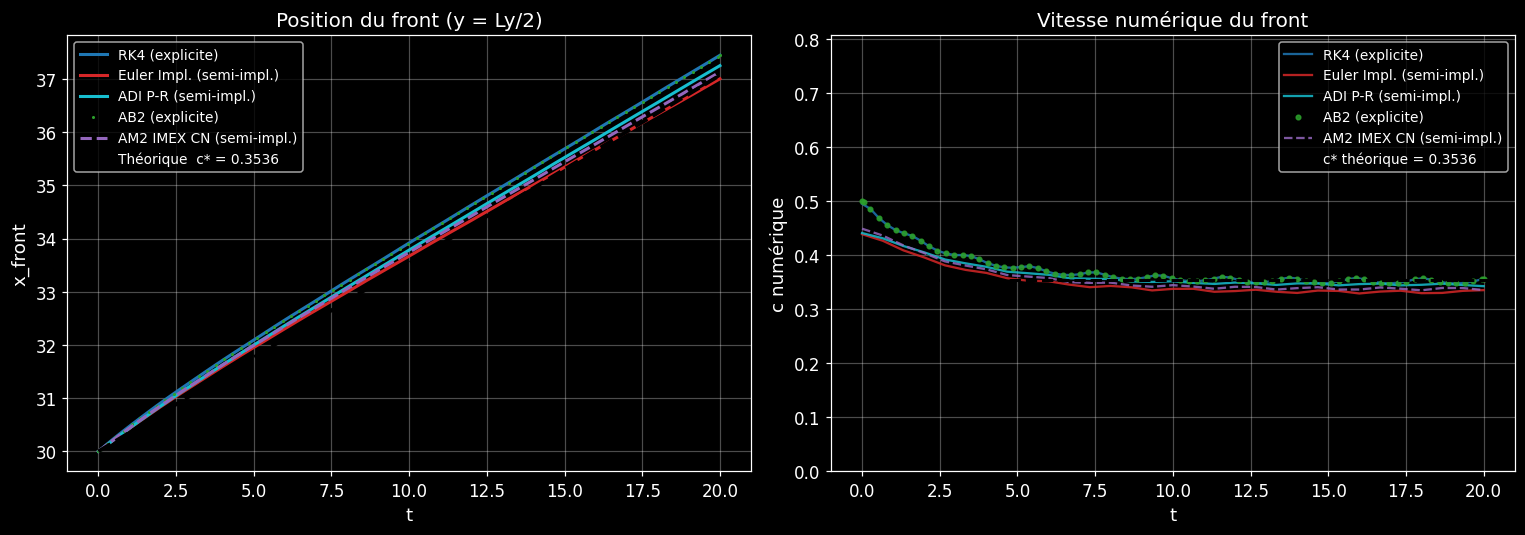

In [ ]:
def plot_front_tracking():
    if 'data' not in RESULTS:
        print("Lancez d'abord la simulation."); return

    data   = RESULTS['data']
    c_th   = RESULTS['c_th']
    T      = RESULTS['params']['T']
    Lx     = RESULTS['params']['Lx']

    COLORS = {'RK4': '#1f77b4', 'EI': '#d62728', 'ADI': '#17becf',
               'AB2': '#2ca02c', 'AM2': '#9467bd'}
    STYLES = {'RK4': '-',  'EI': '-',  'ADI': '-', 'AB2': '.', 'AM2': '--'}
    LABELS = {'RK4': 'RK4 (explicite)',
               'EI':  'Euler Impl. (semi-impl.)',
               'ADI': 'ADI P-R (semi-impl.)',
               'AB2': 'AB2 (explicite)',
               'AM2': 'AM2 IMEX CN (semi-impl.)'}

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # ── Position du front ────────────────────────────────────────────────
    ax = axes[0]
    for sc in data:
        fronts = data[sc]['fronts']
        ts  = np.array([f[0] for f in fronts])
        xfs = np.array([f[1] for f in fronts])
        ax.plot(ts, xfs, STYLES[sc], color=COLORS[sc],
                label=LABELS[sc], linewidth=2, markersize=2)
    t_th = np.linspace(0, T, 200)
    ax.plot(t_th, Lx/2 + c_th * t_th, 'k--', linewidth=2.5,
            label=f'Théorique  c* = {c_th:.4f}')
    ax.set_xlabel('t', fontsize=12); ax.set_ylabel('x_front', fontsize=12)
    ax.set_title('Position du front (y = Ly/2)', fontsize=13)
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

    # ── Estimation de la vitesse numérique ──────────────────────────────
    ax2 = axes[1]
    for sc in data:
        fronts = data[sc]['fronts']
        ts  = np.array([f[0] for f in fronts])
        xfs = np.array([f[1] for f in fronts])
        # Vitesse par différences finies
        valid = ~np.isnan(xfs)
        if valid.sum() > 5:
            v_num = np.gradient(xfs[valid], ts[valid])
            ax2.plot(ts[valid], v_num, STYLES[sc], color=COLORS[sc],
                     label=LABELS[sc], linewidth=1.5, alpha=0.85)
    ax2.axhline(c_th, color='k', ls='--', lw=2,
                label=f'c* théorique = {c_th:.4f}')
    ax2.set_ylim(0, 2 * c_th + 0.1)
    ax2.set_xlabel('t', fontsize=12); ax2.set_ylabel('c numérique', fontsize=12)
    ax2.set_title('Vitesse numérique du front', fontsize=13)
    ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('/tmp/front_tracking.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"c* théorique = √(2D)·(½−a) = √({2*RESULTS['params']['D']:.2f}) × {0.5-RESULTS['params']['a']:.2f} = {c_th:.4f}")

plot_front_tracking()


## 7. Surface 3D du profil final

In [ ]:
def plot_3d_surface():
    if 'data' not in RESULTS:
        print("❌ Lancez d'abord la simulation."); return

    data   = RESULTS['data']
    sys_   = RESULTS['sys']
    X, Y   = sys_['X'], sys_['Y']
    T      = RESULTS['params']['T']

    LABELS = {'RK4': 'RK4', 'EI': 'Euler Impl.', 'ADI': 'ADI P-R',
               'AB2': 'AB2', 'AM2': 'AM2 (IMEX CN)'}

    sl_sc = widgets.Dropdown(
        options=list(LABELS.items()), value='RK4',
        description='Schéma :', style={'description_width': '90px'},
        layout=widgets.Layout(width='280px'),
    )
    out3d = widgets.Output()

    def update_3d(change=None):
        sc     = sl_sc.value
        snaps  = data[sc]['snaps']
        t_f, U = snaps[-1]
        with out3d:
            out3d.clear_output(wait=True)
            fig = plt.figure(figsize=(9, 6))
            ax  = fig.add_subplot(111, projection='3d')
            surf = ax.plot_surface(X, Y, U, cmap='jet', edgecolor='none', alpha=0.9)
            fig.colorbar(surf, ax=ax, shrink=0.5, label='u')
            ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('u')
            ax.set_zlim(0, 1)
            ax.set_title(f'Profil final — {LABELS[sc]}   t = {t_f:.2f}', fontsize=12)
            ax.view_init(elev=30, azim=45)
            plt.tight_layout()
            plt.show()

    sl_sc.observe(update_3d, names='value')
    display(widgets.VBox([sl_sc, out3d]))
    update_3d()

from mpl_toolkits.mplot3d import Axes3D   # noqa
plot_3d_surface()


## 8. Génération de la vidéo animée

In [ ]:
def generate_video(scheme='RK4', fps=15, output_path='/tmp/nagumo_animation.mp4',
                   show_profile=True):
    """Génère une vidéo .mp4 de l'évolution temporelle."""
    if 'data' not in RESULTS:
        print("❌ Lancez d'abord la simulation."); return

    data   = RESULTS['data']
    sys_   = RESULTS['sys']
    X, Y   = sys_['X'], sys_['Y']
    x      = sys_['x']
    c_th   = RESULTS['c_th']
    T      = RESULTS['params']['T']
    Lx     = RESULTS['params']['Lx']
    j_mid  = sys_['Ny'] // 2

    snaps  = data[scheme]['snaps']
    LABELS = {'RK4': 'RK4', 'EI': 'Euler Implicite', 'ADI': 'ADI Peaceman-Rachford',
               'AB2': 'Adams-Bashforth 2', 'AM2': 'AM2 IMEX Crank-Nicolson'}
    COLORS = {'RK4': '#1f77b4', 'EI': '#d62728', 'ADI': '#17becf',
               'AB2': '#2ca02c', 'AM2': '#9467bd'}

    ncols = 2 if show_profile else 1
    fig, axes = plt.subplots(1, ncols, figsize=(7 * ncols, 5.5))
    if ncols == 1: axes = [axes]

    # ── Frame initiale ──────────────────────────────────────────────────
    t0, U0_snap = snaps[0]
    im = axes[0].pcolormesh(X, Y, U0_snap, cmap='RdBu_r', vmin=0, vmax=1, shading='auto')
    ctr_list = [axes[0].contour(X, Y, U0_snap, levels=[0.5], colors='k', linewidths=1.5)]
    plt.colorbar(im, ax=axes[0], label='u')
    axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
    axes[0].set_aspect('equal')
    title_ax = axes[0].set_title('')

    line_num, line_th = None, None
    if show_profile:
        axes[1].set_xlim(0, Lx); axes[1].set_ylim(-0.05, 1.05)
        axes[1].set_xlabel('x'); axes[1].set_ylabel('u(x, Ly/2, t)')
        axes[1].grid(True, alpha=0.3)
        axes[1].axhline(0.5, color='k', ls='--', lw=0.8, label='u = 0.5')
        line_num, = axes[1].plot([], [], color=COLORS[scheme], lw=2,
                                  label=LABELS[scheme])
        line_th,  = axes[1].plot([], [], 'k-', lw=1.5, alpha=0.4,
                                  label=f'c* = {c_th:.4f}')
        axes[1].legend(fontsize=9)
        title_ax2 = axes[1].set_title('')

    plt.tight_layout()

    def animate(frame):
        t_f, U = snaps[frame]
        im.set_array(U.ravel())

        # Retirer l'ancien contour
        for coll in ctr_list[0].collections:
            coll.remove()
        ctr_list[0] = axes[0].contour(X, Y, U, levels=[0.5], colors='k', linewidths=1.5)
        title_ax.set_text(f'{LABELS[scheme]}   —   t = {t_f:.2f} / {T:.1f}')

        if show_profile:
            line_num.set_data(x, U[j_mid, :])
            x_front_th = Lx / 2 + c_th * t_f
            line_th.set_data([x_front_th, x_front_th], [0, 1])
            title_ax2.set_text(f'Profil y = Ly/2   t = {t_f:.2f}')
        return [im]

    print(f"🎬 Création de la vidéo : {len(snaps)} frames  —  schéma {scheme} ...")
    ani = animation.FuncAnimation(fig, animate, frames=len(snaps),
                                   interval=1000 // fps, blit=False)
    writer = animation.FFMpegWriter(fps=fps, bitrate=1800,
                                     extra_args=['-vcodec', 'libx264', '-pix_fmt', 'yuv420p'])
    ani.save(output_path, writer=writer, dpi=130)
    plt.close(fig)
    print(f"✅ Vidéo sauvegardée : {output_path}")
    return output_path


# ── Widgets pour la vidéo ─────────────────────────────────────────────────────
LABELS_VID = {'RK4': 'RK4', 'EI': 'Euler Implicite', 'ADI': 'ADI P-R',
               'AB2': 'AB2', 'AM2': 'AM2 IMEX CN'}

dd_vid  = widgets.Dropdown(
    options=list(LABELS_VID.items()), value='RK4',
    description='Schéma vidéo :', style={'description_width': '130px'},
    layout=widgets.Layout(width='340px'),
)
sl_fps  = widgets.IntSlider(value=15, min=5, max=30, step=1,
                             description='FPS :',
                             style={'description_width': '60px'},
                             layout=widgets.Layout(width='300px'))
chk_prof_vid = widgets.Checkbox(value=True, description='+ profil 1D')
btn_vid = widgets.Button(description='🎬 Générer la vidéo',
                          button_style='info',
                          layout=widgets.Layout(width='240px', height='38px'))
out_vid = widgets.Output()

def on_vid_clicked(b):
    with out_vid:
        out_vid.clear_output(wait=True)
        path = generate_video(
            scheme=dd_vid.value,
            fps=sl_fps.value,
            show_profile=chk_prof_vid.value,
        )
        if path and os.path.exists(path):
            from IPython.display import Video
            display(Video(path, embed=True, width=700))

btn_vid.on_click(on_vid_clicked)
display(widgets.VBox([
    widgets.HTML("<b>Paramètres de la vidéo</b>"),
    widgets.HBox([dd_vid, sl_fps, chk_prof_vid]),
    btn_vid,
    out_vid,
]))


## 9. Vidéo comparaison 4-en-1 (tous schémas simultanément)

In [ ]:
def generate_comparison_video(fps=12, output_path='/tmp/nagumo_comparison.mp4'):
    """Vidéo avec les 4 schémas principaux côte à côte."""
    if 'data' not in RESULTS:
        print("❌ Lancez d'abord la simulation."); return

    data   = RESULTS['data']
    sys_   = RESULTS['sys']
    X, Y   = sys_['X'], sys_['Y']
    T      = RESULTS['params']['T']

    SCHEMES = ['RK4', 'EI', 'ADI', 'AB2', 'AM2']
    LABELS  = {'RK4': 'RK4', 'EI': 'Euler Impl.', 'ADI': 'ADI P-R',
                'AB2': 'AB2', 'AM2': 'AM2 (IMEX CN)'}

    # On se base sur les instants du schéma le plus court (implicite)
    t_ref   = np.array([s[0] for s in data['EI']['snaps']])
    n_frames = len(t_ref)

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.flatten()

    ims, ctrs = [], []
    for k, sc in enumerate(SCHEMES):
        t0, U0s = data[sc]['snaps'][0]
        im = axes[k].pcolormesh(X, Y, U0s, cmap='RdBu_r', vmin=0, vmax=1, shading='auto')
        plt.colorbar(im, ax=axes[k])
        ctrs.append([axes[k].contour(X, Y, U0s, levels=[0.5], colors='k', linewidths=1.2)])
        axes[k].set_aspect('equal')
        axes[k].set_xlabel('x'); axes[k].set_ylabel('y')
        ims.append(im)
    axes[5].axis('off')

    sup = plt.suptitle('', fontsize=13)
    plt.tight_layout()

    def animate(frame):
        t_target = t_ref[frame]
        sup.set_text(f'Nagumo 2D — t = {t_target:.2f} / {T:.1f}')
        for k, sc in enumerate(SCHEMES):
            snaps = data[sc]['snaps']
            ts    = np.array([s[0] for s in snaps])
            idx   = int(np.argmin(np.abs(ts - t_target)))
            _, U  = snaps[idx]
            ims[k].set_array(U.ravel())
            for coll in ctrs[k][0].collections:
                coll.remove()
            ctrs[k][0] = axes[k].contour(X, Y, U, levels=[0.5], colors='k', linewidths=1.2)
            axes[k].set_title(f'{LABELS[sc]}  t={t_target:.1f}', fontsize=10)
        return ims

    print(f"🎬 Vidéo comparaison : {n_frames} frames ...")
    ani = animation.FuncAnimation(fig, animate, frames=n_frames,
                                   interval=1000 // fps, blit=False)
    writer = animation.FFMpegWriter(fps=fps, bitrate=2200,
                                     extra_args=['-vcodec', 'libx264', '-pix_fmt', 'yuv420p'])
    ani.save(output_path, writer=writer, dpi=110)
    plt.close(fig)
    print(f"✅ Vidéo comparaison : {output_path}")
    return output_path


btn_cmp_vid = widgets.Button(description='🎬 Vidéo 5-en-1 (tous schémas)',
                              button_style='warning',
                              layout=widgets.Layout(width='320px', height='38px'))
sl_fps2  = widgets.IntSlider(value=10, min=4, max=24, step=1,
                              description='FPS :', style={'description_width': '50px'},
                              layout=widgets.Layout(width='260px'))
out_cmp_vid = widgets.Output()

def on_cmp_vid(b):
    with out_cmp_vid:
        out_cmp_vid.clear_output(wait=True)
        path = generate_comparison_video(fps=sl_fps2.value)
        if path and os.path.exists(path):
            display(Video(path, embed=True, width=800))

btn_cmp_vid.on_click(on_cmp_vid)
display(widgets.HBox([btn_cmp_vid, sl_fps2]), out_cmp_vid)


Output()

## 10. Tableau récapitulatif

In [ ]:
def print_summary():
    if 'data' not in RESULTS:
        print("❌ Lancez d'abord la simulation."); return

    data    = RESULTS['data']
    c_th    = RESULTS['c_th']
    params  = RESULTS['params']
    sys_    = RESULTS['sys']

    print("=" * 70)
    print(f"  PARAMÈTRES : D={params['D']}, a={params['a']}, T={params['T']}, "
          f"Nx=Ny={params['Nx']}, Lx={params['Lx']}")
    print(f"  Vitesse théorique c* = √(2D)·(½−a) = {c_th:.5f}")
    print("=" * 70)
    print(f"{'Schéma':<20} {'dt':>10} {'Nt':>8} {'x_front(T)':>14} {'c_num':>10} {'err c':>8}")
    print("-" * 70)
    Lx = params['Lx']
    for sc, res in data.items():
        fronts = [f[1] for f in res['fronts']]
        xf = next((v for v in reversed(fronts) if not np.isnan(v)), np.nan)
        t_arr = np.array([f[0] for f in res['fronts']])
        xf_arr = np.array([f[1] for f in res['fronts']])
        valid = ~np.isnan(xf_arr)
        if valid.sum() > 2:
            T_f = t_arr[valid][-1]
            c_num = (xf_arr[valid][-1] - Lx / 2) / T_f if T_f > 0 else np.nan
        else:
            c_num = np.nan
        err = abs(c_num - c_th) / c_th * 100 if not np.isnan(c_num) else np.nan
        label_type = 'expl.' if sc in ['RK4', 'AB2'] else 'semi-impl.'
        print(f"  {sc:<6}({label_type:<10}) {res['dt']:>10.5f} {res['Nt']:>8d} "
              f"{xf:>14.4f} {c_num:>10.5f} {err:>7.2f}%")
    print("=" * 70)

print_summary()


  PARAMÈTRES : D=1.0000000000000002, a=0.25, T=19.999999999999996, Nx=Ny=80, Lx=60.0
  Vitesse théorique c* = √(2D)·(½−a) = 0.35355
Schéma                       dt       Nt     x_front(T)      c_num    err c
----------------------------------------------------------------------
  RK4   (expl.     )    0.06734      297        37.4469    0.37235    5.32%
  EI    (semi-impl.)    0.66667       30        37.0046    0.35023    0.94%
  ADI   (semi-impl.)    0.66667       30        37.2526    0.36263    2.57%
  AB2   (expl.     )    0.06734      297        37.4470    0.37235    5.32%
  AM2   (semi-impl.)    0.66667       30        37.1324    0.35662    0.87%
